# Polynomial Regression Using Different Optimization Algorithms

In [1]:
!pip install ucimlrepo

## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading

In [3]:
try:
    # Primary source: UCI (internet)
    auto_mpg = fetch_ucirepo(id=9)
    X_data = auto_mpg.data.features
    y_data = auto_mpg.data.targets

    df = X_data.copy()
    df["mpg"] = y_data["mpg"]

    print("Loaded from UCI (internet)")

except Exception as e:
    # Backup source: Kaggle Dataset
    print("UCI failed, loading Kaggle backup:", e)

    import os

    for root, dirs, files in os.walk("/kaggle/input"):
        if "auto-mpg.data" in files:
            backup_path = os.path.join(root, "auto-mpg.data")
            break

    df = pd.read_csv(
        backup_path,
        names=["mpg", "cylinders", "displacement", "horsepower",
               "weight", "acceleration", "model_year", "origin", "car_name"],
        na_values="?",
        sep=r"\s+",
        skipinitialspace=True
    )

df = df[["horsepower", "mpg"]]

df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["mpg"] = pd.to_numeric(df["mpg"], errors="coerce")

display(df.head())
print("Dataset shape:", df.shape)

Loaded from UCI (internet)


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


Dataset shape: (398, 2)


## 3. Exploratory Data Analysis (EDA)

In [4]:
# Dataset Information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         398 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB

Statistical Summary:


,horsepower,mpg
count,392.000000,398.000000
mean,104.469388,23.514573
std,38.491160,7.815984
min,46.000000,9.000000
25%,75.000000,17.500000
50%,93.500000,23.000000
75%,126.000000,29.000000
max,230.000000,46.600000



Missing Values:
horsepower    6
mpg           0
dtype: int64


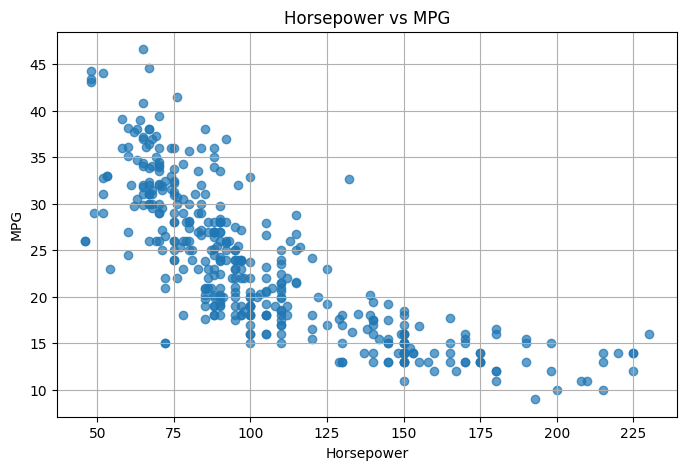

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(df["horsepower"], df["mpg"], alpha=0.7)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")

plt.grid(True)
plt.show()


## 4. Data Preprocessing

4.1 Separate Features and Target

4.2 Split Data into Training and Testing Sets

4.3 Handle Missing Values

4.4 Polynomial Feature Transformation

4.5 Feature Scaling

4.6 Add Bias Term

In [6]:

X = df[["horsepower"]].values
y = df[["mpg"]].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (398, 1)
y shape: (398, 1)


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 318
Testing samples: 80


In [8]:

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing values handled successfully!")


Missing values handled successfully!


In [9]:

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original features:", X_train.shape)
print("Polynomial features:", X_train_poly.shape)

print("\nFirst 5 polynomial samples:")
print(X_train_poly[:5])


Original features: (318, 1)
Polynomial features: (318, 2)

First 5 polynomial samples:
[[  150. 22500.]
 [   88.  7744.]
 [   68.  4624.]
 [   60.  3600.]
 [   95.  9025.]]


In [10]:

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Scale the target values too
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Feature scaling completed!")


Feature scaling completed!


In [11]:

# Add bias column to training and testing data

X_train_model = np.c_[
    np.ones((X_train_scaled.shape[0], 1)),
    X_train_scaled
]

X_test_model = np.c_[
    np.ones((X_test_scaled.shape[0], 1)),
    X_test_scaled
]

print("Training shape:", X_train_model.shape)
print("Testing shape:", X_test_model.shape)


Training shape: (318, 3)
Testing shape: (80, 3)


## 5. Model and Loss Function

In [12]:

# Initialize model parameters

n_features = X_train_model.shape[1]

initial_weights = np.zeros((n_features, 1))

print("Initial weights:")
print(initial_weights)


Initial weights:
[[0.]
 [0.]
 [0.]]


In [13]:

def compute_loss(X, y, weights):

    predictions = X @ weights

    #Mean Squared Error (MSE)
    loss = np.mean((predictions - y) ** 2)

    return loss


## 6. Optimization Algorithm

6.2 Stochastic Gradient Descent (SGD)


In [14]:

def compute_gradient(X, y, weights):

    m = len(y)

    predictions = X @ weights

    gradient = (2 / m) * X.T @ (predictions - y)

    return gradient


## 7. Train the Model

In [15]:
def train_sgd(learning_rate=0.01, epochs=500,
              use_momentum=False, beta=0.9, seed=42):

    weights = np.zeros((X_train_model.shape[1], 1))
    velocity = np.zeros_like(weights)

    loss_history = []

    # Same seed -> both runs (with / without momentum) see the same shuffles
    rng = np.random.default_rng(seed)
    m = len(y_train_scaled)

    start_time = time.time()

    for epoch in range(epochs):

        # Shuffle the sample order every epoch
        indices = rng.permutation(m)

        for i in indices:

            # Select one training sample
            X_sample = X_train_model[i:i+1]
            y_sample = y_train_scaled[i:i+1]

            # Calculate gradient
            gradient = compute_gradient(
                X_sample,
                y_sample,
                weights
            )

            # Update weights
            if use_momentum:
                velocity = beta * velocity + gradient
                weights -= learning_rate * velocity
            else:
                weights -= learning_rate * gradient

        # Calculate loss after each epoch
        epoch_loss = compute_loss(
            X_train_model,
            y_train_scaled,
            weights
        )

        loss_history.append(epoch_loss)

    training_time = time.time() - start_time

    return weights, loss_history, training_time

In [16]:
# 1. SGD without Momentum
weights_sgd, loss_history_sgd, training_time_sgd = train_sgd(
    use_momentum=False
)

# 2. SGD with Momentum
weights_momentum, loss_history_momentum, training_time_momentum = train_sgd(
    use_momentum=True
)

# Print Results
print("SGD Final Loss:", loss_history_sgd[-1])
print("SGD Training Time:", training_time_sgd)
print("SGD Final Weights:")
print(weights_sgd)

print("\nSGD + Momentum Final Loss:", loss_history_momentum[-1])
print("SGD + Momentum Training Time:", training_time_momentum)
print("SGD + Momentum Final Weights:")
print(weights_momentum)

SGD Final Loss: 0.33779713278107115
SGD Training Time: 1.1998929977416992
SGD Final Weights:
[[ 0.01284965]
 [-2.22439493]
 [ 1.453135  ]]

SGD + Momentum Final Loss: 0.39369872366956826
SGD + Momentum Training Time: 1.5344133377075195
SGD + Momentum Final Weights:
[[ 0.08724815]
 [-2.40339146]
 [ 1.43934087]]


## 8. Visualizing Training Loss

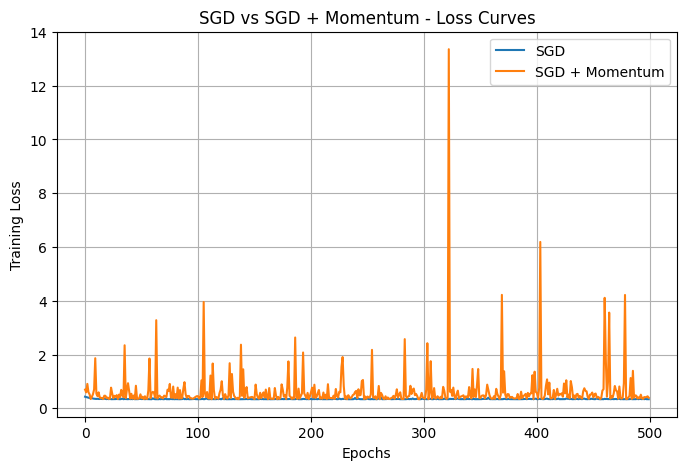

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history_sgd, label="SGD")
plt.plot(loss_history_momentum, label="SGD + Momentum")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("SGD vs SGD + Momentum - Loss Curves")

plt.legend()
plt.grid(True)
plt.show()

## 9. Model Evaluation

In [18]:
# Predictions using SGD
y_pred_sgd_scaled = X_test_model @ weights_sgd

# Predictions using SGD + Momentum
y_pred_momentum_scaled = X_test_model @ weights_momentum

# Convert predictions back to original scale
y_pred_sgd = scaler_y.inverse_transform(y_pred_sgd_scaled)
y_pred_momentum = scaler_y.inverse_transform(y_pred_momentum_scaled)

# Evaluate SGD
print("SGD Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_sgd))
print("MAE:", mean_absolute_error(y_test, y_pred_sgd))
print("R2 Score:", r2_score(y_test, y_pred_sgd))

# Evaluate SGD + Momentum
print("\nSGD + Momentum Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_momentum))
print("MAE:", mean_absolute_error(y_test, y_pred_momentum))
print("R2 Score:", r2_score(y_test, y_pred_momentum))

SGD Evaluation:
MSE: 14.13404937087669
MAE: 2.949289168001875
R2 Score: 0.7371213644592834

SGD + Momentum Evaluation:
MSE: 18.922872937829734
MAE: 3.451643266287147
R2 Score: 0.6480542208479293


## 10. Compare Results

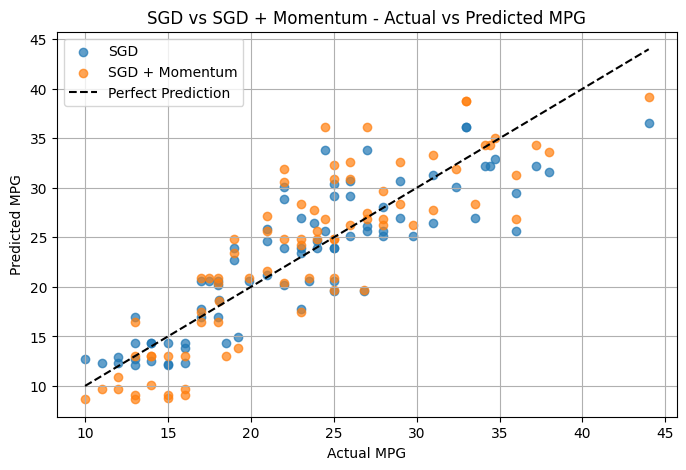

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_sgd, label="SGD", alpha=0.7)
plt.scatter(y_test, y_pred_momentum, label="SGD + Momentum", alpha=0.7)

# Perfect prediction line
min_value = y_test.min()
max_value = y_test.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'k--',
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("SGD vs SGD + Momentum - Actual vs Predicted MPG")

plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this notebook, Polynomial Regression (degree 2) was implemented using Stochastic Gradient Descent (SGD) to predict fuel efficiency (MPG) from horsepower. The dataset underwent the same preprocessing steps used in the Gradient Descent experiment to ensure a fair comparison.

Two experiments were conducted: SGD without Momentum and SGD with Momentum. Samples are shuffled every epoch and a fixed seed is used, so results are reproducible. Because SGD updates the weights after every single sample, its loss curve is noisy and it is much slower in wall-clock time than full-batch methods (500 epochs x 318 updates).

Momentum with beta = 0.9 effectively multiplies the step size by up to 10, which in the per-sample setting amplifies gradient noise; at the same learning rate it is therefore expected to hover around the minimum rather than settle on it, and may do worse than plain SGD. A smaller learning rate (or a decaying one) would be needed to benefit from momentum here. Both models were evaluated with MSE, MAE and R² on the test set; re-run the notebook for the final numbers.